In [ ]:
import numpy as np
import pandas as pd

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import cosine_similarity

from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

In [ ]:
documents = {
    "D1": "Information retrieval system",
    "D2": "Retrieval models and ranking",
    "D3": "Machine learning algorithms",
    "D4": "Clustering and classification",
    "D5": "Search engines and retrieval",
    "D6": "Deep learning for NLP"
}

test_doc = ["Retrieval and search systems"]

In [ ]:
vectorizer = TfidfVectorizer(stop_words='english')
X = vectorizer.fit_transform(documents.values())

print("TF-IDF Matrix:\n", X.toarray())

TF-IDF Matrix:
 [[0.         0.         0.         0.         0.         0.82219037
  0.         0.         0.         0.         0.         0.56921261
  0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.63509072 0.         0.63509072 0.4396812
  0.        ]
 [0.61171251 0.         0.         0.         0.         0.
  0.50161301 0.61171251 0.         0.         0.         0.
  0.        ]
 [0.         0.70710678 0.70710678 0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.        ]
 [0.         0.         0.         0.         0.63509072 0.
  0.         0.         0.         0.         0.         0.4396812
  0.63509072]
 [0.         0.         0.         0.61171251 0.         0.
  0.50161301 0.         0.         0.61171251 0.         0.
  0.        ]]


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X)

labels = kmeans.labels_

In [ ]:
for doc, label in zip(documents.keys(), labels):
    print(f"{doc} -> Cluster {label}")

D1 -> Cluster 2
D2 -> Cluster 2
D3 -> Cluster 0
D4 -> Cluster 1
D5 -> Cluster 1
D6 -> Cluster 0


In [ ]:
test_vector = vectorizer.transform(test_doc)
test_cluster = kmeans.predict(test_vector)

print("\nTest Document Cluster:", test_cluster[0])


Test Document Cluster: 1


In [ ]:
cos_sim = cosine_similarity(X)
print("\nCosine Similarity Matrix:\n", cos_sim)


Cosine Similarity Matrix:
 [[1.         0.25027208 0.         0.         0.25027208 0.        ]
 [0.25027208 1.         0.         0.         0.19331955 0.        ]
 [0.         0.         1.         0.         0.         0.25161561]
 [0.         0.         0.         1.         0.         0.        ]
 [0.25027208 0.19331955 0.         0.         1.         0.        ]
 [0.         0.         0.25161561 0.         0.         1.        ]]


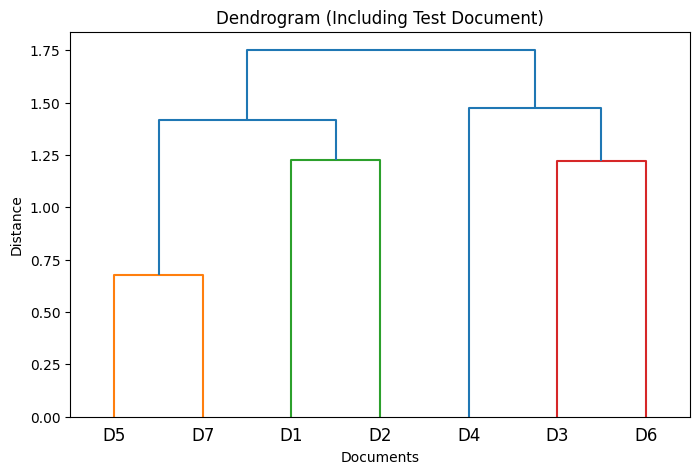

In [ ]:
all_vectors = np.vstack([X.toarray(), test_vector.toarray()])

all_labels = list(documents.keys()) + ["D7"]

linked = linkage(all_vectors, method='ward')

plt.figure(figsize=(8, 5))
dendrogram(linked, labels=all_labels)
plt.title("Dendrogram (Including Test Document)")
plt.xlabel("Documents")
plt.ylabel("Distance")
plt.show()

In [ ]:
test_doc_vs_all_docs_similarity = cosine_similarity(test_vector, X)

cos_sim_df = pd.DataFrame(
    test_doc_vs_all_docs_similarity.flatten(),
    index=documents.keys(),
    columns=["TestDoc"]
)

df = pd.DataFrame({
    'DocID': list(documents.keys()),
    'Cluster': labels
})

most_similar_doc = cos_sim_df["TestDoc"].idxmax()
cluster_of_test = df[df["DocID"] == most_similar_doc]["Cluster"].values[0]

print("Most similar doc:", most_similar_doc)
print("Final Cluster:", cluster_of_test)

Most similar doc: D5
Final Cluster: 1
